# Regresión No Lineal – Histórico de ventas
y = log_neto (igual en los 4 modelos). Variables en escala logarítmica (log10).


- Cuadrática - log_unidades
- Exponencial - log_unidades
- Cuadrática - log_precio
- Exponencial - log_precio

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score

## Carga y limpieza

In [2]:
df =  pd.read_excel("Datos_Complementarios_CLV.xlsx", sheet_name="Histórico_Ventas")

df.columns = df.columns.str.strip()
for c in ['precio_unitario', 'total_unidades', 'total_neto']:
    df[c] = pd.to_numeric(df[c], errors='coerce')

# Solo valores positivos
df = df.dropna(subset=['precio_unitario', 'total_unidades', 'total_neto'])
df = df[(df['precio_unitario'] > 0) & (df['total_unidades'] > 0) & (df['total_neto'] > 0)]

# Quitamos extremos (arriba del percentil 99)
df = df[(df['precio_unitario'] <= df['precio_unitario'].quantile(0.99)) &
        (df['total_unidades'] <= df['total_unidades'].quantile(0.99))].reset_index(drop=True)

# Escala logarítmica
df['log_precio']   = np.log10(df['precio_unitario'])
df['log_unidades'] = np.log10(df['total_unidades'])
df['log_neto']     = np.log10(df['total_neto'])
print(df.shape)

(19620, 17)


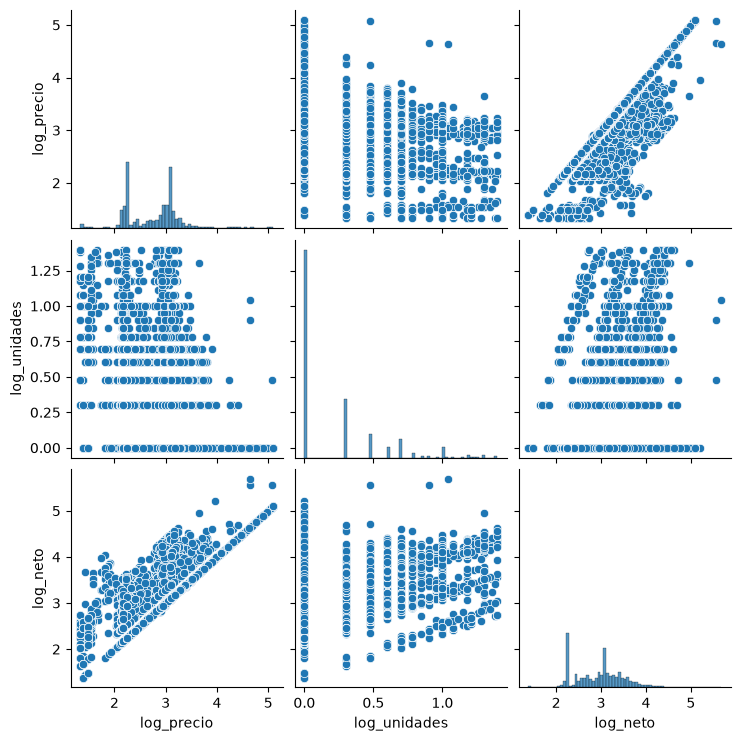

In [3]:
sns.pairplot(df[['log_precio', 'log_unidades', 'log_neto']])

## Variables

In [4]:
y = df['log_neto']                 # y para los 4 modelos
x_unid = df[['log_unidades']]      # x Modelos 1 y 2
x_precio = df[['log_precio']]      # x Modelos 3 y 4

## Funciones de ajuste
- Cuadrática: `y = a*x^2 + b*x + c`
- Exponencial: `y = a*exp(-b*x) + c`

In [5]:
def func1(x, a, b, c):
    return a*x**2 + b*x + c

def func2(x, a, b, c):
    return a*np.exp(-b*x) + c

def p0_exp(xs, ys):
    # Valores iniciales para la exponencial
    xs, ys = np.asarray(xs, float), np.asarray(ys, float)
    a0 = (ys.max() - ys.min()) / (np.e - 1)
    return [a0, -1.0/xs.max(), ys.min() - a0]

## MODELO 1: Cuadrática (x = log_unidades)

In [6]:
x1 = df[['log_unidades']]

In [7]:
# Ajuste
parametros1, covs1 = curve_fit(func1, df['log_unidades'], df['log_neto'])

In [8]:
# Coeficientes
parametros1

array([-0.3263684 ,  1.0171563 ,  2.79993983])

In [9]:
# Predicciones
y_pred1 = func1(x1, *parametros1)
y_pred1

,log_unidades
0,2.79994
1,2.79994
2,2.79994
3,2.79994
4,2.79994
...,...
19615,2.79994
19616,2.79994
19617,2.79994
19618,2.79994


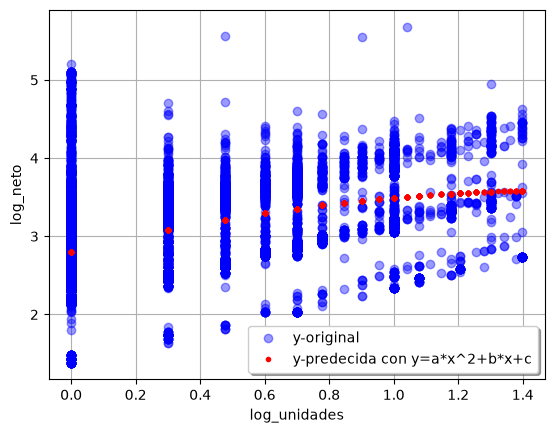

In [10]:
# Gráfica
plt.plot(x1, y, 'o', color='blue', alpha=0.4, label='y-original')
plt.plot(x1, y_pred1, 'o', color='red', markersize=3, label='y-predecida con y=a*x^2+b*x+c')
plt.xlabel('log_unidades')
plt.ylabel('log_neto')
plt.legend(loc='best', fancybox=True, shadow=True)
plt.grid(True)
plt.show()

In [11]:
# Coeficiente de determinación
R2_Modelo1 = r2_score(y, y_pred1)
R2_Modelo1

0.1743949646390075

In [12]:
# Coeficiente de correlación
R1 = np.sqrt(abs(R2_Modelo1))
R1

np.float64(0.4176062315615124)

## MODELO 2: Exponencial (x = log_unidades)

In [13]:
x2 = df[['log_unidades']]

In [14]:
# Ajuste
parametros2, covs2 = curve_fit(func2, df['log_unidades'], df['log_neto'], p0=p0_exp(df['log_unidades'], df['log_neto']), maxfev=50000)

In [15]:
# Coeficientes
parametros2

array([ 2.29345022e+03, -3.11551326e-04, -2.29063415e+03])

In [16]:
# Predicciones
y_pred2 = func2(x2, *parametros2)
y_pred2

,log_unidades
0,2.816075
1,2.816075
2,2.816075
3,2.816075
4,2.816075
...,...
19615,2.816075
19616,2.816075
19617,2.816075
19618,2.816075


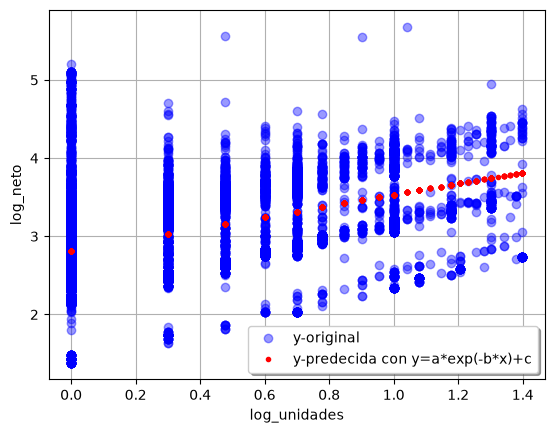

In [17]:
# Gráfica
plt.plot(x2, y, 'o', color='blue', alpha=0.4, label='y-original')
plt.plot(x2, y_pred2, 'o', color='red', markersize=3, label='y-predecida con y=a*exp(-b*x)+c')
plt.xlabel('log_unidades')
plt.ylabel('log_neto')
plt.legend(loc='best', fancybox=True, shadow=True)
plt.grid(True)
plt.show()

In [18]:
# Coeficiente de determinación
R2_Modelo2 = r2_score(y, y_pred2)
R2_Modelo2

0.16967170753603722

In [19]:
# Coeficiente de correlación
R2 = np.sqrt(abs(R2_Modelo2))
R2

np.float64(0.4119122570840023)

## MODELO 3: Cuadrática (x = log_precio)

In [20]:
x3 = df[['log_precio']]

In [21]:
# Ajuste
parametros3, covs3 = curve_fit(func1, df['log_precio'], df['log_neto'])

In [22]:
# Coeficientes
parametros3

array([0.05859026, 0.53863409, 1.03963962])

In [23]:
# Predicciones
y_pred3 = func1(x3, *parametros3)
y_pred3

,log_precio
0,3.288157
1,2.926544
2,2.926544
3,2.926544
4,2.926544
...,...
19615,4.777874
19616,2.537409
19617,2.537429
19618,2.537429


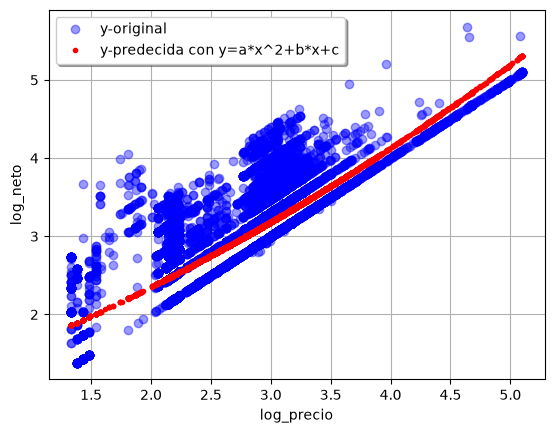

In [24]:
# Gráfica
plt.plot(x3, y, 'o', color='blue', alpha=0.4, label='y-original')
plt.plot(x3, y_pred3, 'o', color='red', markersize=3, label='y-predecida con y=a*x^2+b*x+c')
plt.xlabel('log_precio')
plt.ylabel('log_neto')
plt.legend(loc='best', fancybox=True, shadow=True)
plt.grid(True)
plt.show()

In [25]:
# Coeficiente de determinación
R2_Modelo3 = r2_score(y, y_pred3)
R2_Modelo3

0.662863171920143

In [26]:
# Coeficiente de correlación
R3 = np.sqrt(abs(R2_Modelo3))
R3

np.float64(0.8141640939762346)

## MODELO 4: Exponencial (x = log_precio)

In [27]:
x4 = df[['log_precio']]

In [28]:
# Ajuste
parametros4, covs4 = curve_fit(func2, df['log_precio'], df['log_neto'], p0=p0_exp(df['log_precio'], df['log_neto']), maxfev=50000)

In [29]:
# Coeficientes
parametros4

array([ 5.75123587, -0.11049406, -4.82638703])

In [30]:
# Predicciones
y_pred4 = func2(x4, *parametros4)
y_pred4

,log_precio
0,3.289858
1,2.929524
2,2.929524
3,2.929524
4,2.929524
...,...
19615,4.754906
19616,2.537159
19617,2.537180
19618,2.537180


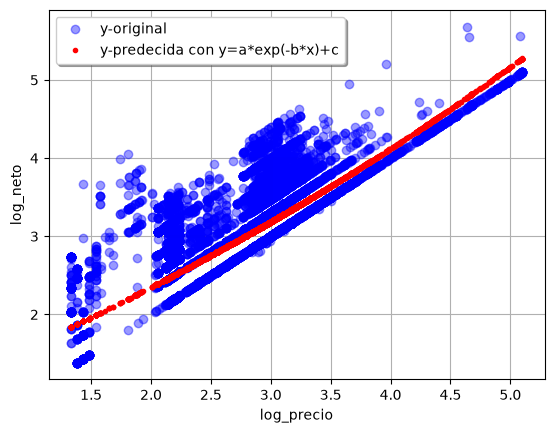

In [31]:
# Gráfica
plt.plot(x4, y, 'o', color='blue', alpha=0.4, label='y-original')
plt.plot(x4, y_pred4, 'o', color='red', markersize=3, label='y-predecida con y=a*exp(-b*x)+c')
plt.xlabel('log_precio')
plt.ylabel('log_neto')
plt.legend(loc='best', fancybox=True, shadow=True)
plt.grid(True)
plt.show()

In [32]:
# Coeficiente de determinación
R2_Modelo4 = r2_score(y, y_pred4)
R2_Modelo4

0.66242889875506

In [33]:
# Coeficiente de correlación
R4 = np.sqrt(abs(R2_Modelo4))
R4

np.float64(0.8138973514854683)

## Tabla de coeficientes de determinación (R²) y correlación (R)

In [34]:
tabla = pd.DataFrame({
    'Modelo': [1, 2, 3, 4],
    'Función': ['Cuadrática', 'Exponencial', 'Cuadrática', 'Exponencial'],
    'Ecuación': ['y=a*x^2+b*x+c', 'y=a*exp(-b*x)+c', 'y=a*x^2+b*x+c', 'y=a*exp(-b*x)+c'],
    'x': ['log_unidades', 'log_unidades', 'log_precio', 'log_precio'],
    'y': 'log_neto',
    'a': [parametros1[0], parametros2[0], parametros3[0], parametros4[0]],
    'b': [parametros1[1], parametros2[1], parametros3[1], parametros4[1]],
    'c': [parametros1[2], parametros2[2], parametros3[2], parametros4[2]],
    'R2': [R2_Modelo1, R2_Modelo2, R2_Modelo3, R2_Modelo4],
    'R': [R1, R2, R3, R4],
})
tabla[['a', 'b', 'c', 'R2', 'R']] = tabla[['a', 'b', 'c', 'R2', 'R']].round(4)
tabla

,Modelo,Función,Ecuación,x,y,a,b,c,R2,R
0,1,Cuadrática,y=a*x^2+b*x+c,log_unidades,log_neto,-0.3264,1.0172,2.7999,0.1744,0.4176
1,2,Exponencial,y=a*exp(-b*x)+c,log_unidades,log_neto,2293.4502,-0.0003,-2290.6341,0.1697,0.4119
2,3,Cuadrática,y=a*x^2+b*x+c,log_precio,log_neto,0.0586,0.5386,1.0396,0.6629,0.8142
3,4,Exponencial,y=a*exp(-b*x)+c,log_precio,log_neto,5.7512,-0.1105,-4.8264,0.6624,0.8139


In [ ]:
# Mejor modelo y exportar la tabla
print("Mejor modelo:", int(tabla.loc[tabla['R2'].idxmax(), 'Modelo']))

Mejor modelo: 3
